# VaDeSC on simulated data

Benchmarks VaDeSC against the baseline models on the
nonlinear simulator from the original VaDeSC repo (`simulate_nonlin_profile_surv`).
True cluster labels are known, so we also report ARI (and log-rank) for clustering.

The full run takes roughly 1.5 h on a GPU. Set `QUICK = True` for a short check.

Data size: 60,000 patients, 1,000 features, one seed. Notebook 03 uses 10,000 patients and 5 seeds, so the numbers (e.g. ARI) are not directly comparable between the two.


In [2]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from src.baselines import run_cox, run_weibull_aft
from src.data import load_simulated
from src.metrics import logrank_chi2
from src.vadesc import DEVICE, evaluate_vadesc, train_vadesc

QUICK = False
EPOCHS = 40 if QUICK else 1000          
N_SEEDS = 2 if QUICK else 5
N = 800 if QUICK else 60_000          
P = 50 if QUICK else 1000             
K = 3                                 
D_LAT = 8 if QUICK else 16            
print("device:", DEVICE, "| QUICK:", QUICK, f"| n={N}, p={P}, K={K}, d_lat={D_LAT}, epochs={EPOCHS}")

device: mps | QUICK: False | n=60000, p=1000, K=3, d_lat=16, epochs=1000


## Data

One representative draw (seed 0). True clusters drive different survival curves.

train (42000, 1000), val (6000, 1000), test (12000, 1000)
event rate 70.1% | median time 0.04
true cluster sizes (test): [3983, 4064, 3953]


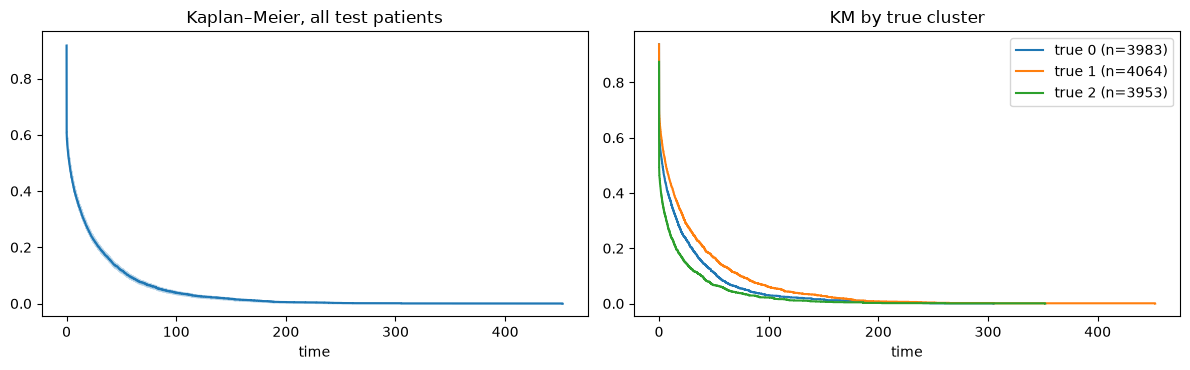

In [3]:
sim = load_simulated(n=N, p=P, k=K, d_lat=D_LAT, seed=0)
print(f"train {sim.X_tr.shape}, val {sim.X_va.shape}, test {sim.X_te.shape}")
print(f"event rate {sim.e_tr.mean():.1%} | median time {np.median(sim.t_tr):.2f}")
print("true cluster sizes (test):", np.bincount(sim.clusters_true_te).tolist())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
KaplanMeierFitter().fit(sim.t_te, sim.e_te).plot_survival_function(ax=ax[0], legend=False)
ax[0].set(title="Kaplan–Meier, all test patients", xlabel="time")
for k in np.unique(sim.clusters_true_te):
    m = sim.clusters_true_te == k
    KaplanMeierFitter(label=f"true {k} (n={m.sum()})").fit(sim.t_te[m], sim.e_te[m]) \
        .plot_survival_function(ax=ax[1], ci_show=False)
ax[1].set(title="KM by true cluster", xlabel="time")
plt.tight_layout(); plt.show()

## Baselines and VaDeSC

Single-seed comparison on the draw above (same models as the SUPPORT notebook, minus RSF):
Cox PH, Weibull AFT, VaDeSC, VaDE (no survival), and k-means. VaDeSC uses `K=3`,
`weibull_k=1` as in the paper's sim config. 

In [4]:
import time
from pathlib import Path

# survival baselines + VaDeSC + VaDE + k-means.
print(f"Training VaDeSC ({EPOCHS} epochs)…", flush=True)
t0 = time.time()
vadesc = train_vadesc(sim, K=K, d_lat=D_LAT, weibull_k=1.0, epochs=EPOCHS, seed=0, verbose=True)
print(f"VaDeSC done in {(time.time() - t0) / 60:.1f} min", flush=True)

results = {}
results["VaDeSC"], clusters, z_te = evaluate_vadesc(vadesc, sim)

print("Training VaDE (no survival)…", flush=True)
t0 = time.time()
results["VaDE"], cl_vade, _ = evaluate_vadesc(
    train_vadesc(sim, K=K, d_lat=D_LAT, survival=False, epochs=EPOCHS, seed=0, verbose=False),
    sim,
)
print(f"  VaDE done in {(time.time() - t0) / 60:.1f} min", flush=True)

cl_km = KMeans(K, n_init=10, random_state=0).fit(sim.X_tr).predict(sim.X_te)
results["k-means"] = {
    "ARI": adjusted_rand_score(sim.clusters_true_te, cl_km),
    "log-rank chi2": logrank_chi2(sim, cl_km),
}

for name, fn in [
    ("Cox PH", lambda: run_cox(sim)),
    ("Weibull AFT", lambda: run_weibull_aft(sim)),
]:
    print(f"Fitting {name}…", flush=True)
    t0 = time.time()
    results[name] = fn()
    print(f"  {name} done in {(time.time() - t0) / 60:.1f} min", flush=True)

out = Path("../results"); out.mkdir(exist_ok=True)
table = pd.DataFrame(results).T.reindex(["Cox PH", "Weibull AFT", "VaDeSC", "VaDE", "k-means"])
table.to_csv(out / "sim_seed0_single.csv")
print("saved", out / "sim_seed0_single.csv")
table.round(3)

Training VaDeSC (1000 epochs)…
epoch   25 | -ELBO   143.079 | val C-index 0.699 | ARI 0.099
epoch   50 | -ELBO   134.016 | val C-index 0.739 | ARI 0.171
epoch   75 | -ELBO   127.425 | val C-index 0.760 | ARI 0.253
epoch  100 | -ELBO   122.058 | val C-index 0.770 | ARI 0.294
epoch  125 | -ELBO   117.084 | val C-index 0.782 | ARI 0.343
epoch  150 | -ELBO   113.035 | val C-index 0.795 | ARI 0.398
epoch  175 | -ELBO   109.616 | val C-index 0.814 | ARI 0.455
epoch  200 | -ELBO   106.842 | val C-index 0.827 | ARI 0.485
epoch  225 | -ELBO   104.817 | val C-index 0.833 | ARI 0.519
epoch  250 | -ELBO   103.243 | val C-index 0.843 | ARI 0.548
epoch  275 | -ELBO   101.891 | val C-index 0.846 | ARI 0.565
epoch  300 | -ELBO   100.575 | val C-index 0.848 | ARI 0.575
epoch  325 | -ELBO    99.914 | val C-index 0.849 | ARI 0.576
epoch  350 | -ELBO    99.174 | val C-index 0.849 | ARI 0.573
epoch  375 | -ELBO    98.252 | val C-index 0.847 | ARI 0.580
epoch  400 | -ELBO    98.037 | val C-index 0.848 | ARI

,C-index,IBS,log-rank chi2,ARI
Cox PH,0.751,0.166,NaN,NaN
Weibull AFT,0.742,0.186,NaN,NaN
VaDeSC,0.843,0.138,328.666,0.594
VaDE,NaN,NaN,343.312,0.591
k-means,NaN,NaN,205.897,0.050


## Clusters

Predicted clusters vs true labels (ARI), KM separation, and latent PCA.

ARI(VaDeSC, true) = 0.594 | log-rank chi2 = 328.7
label map (pred → true): {np.int64(0): np.int64(1), np.int64(1): np.int64(0), np.int64(2): np.int64(2)}


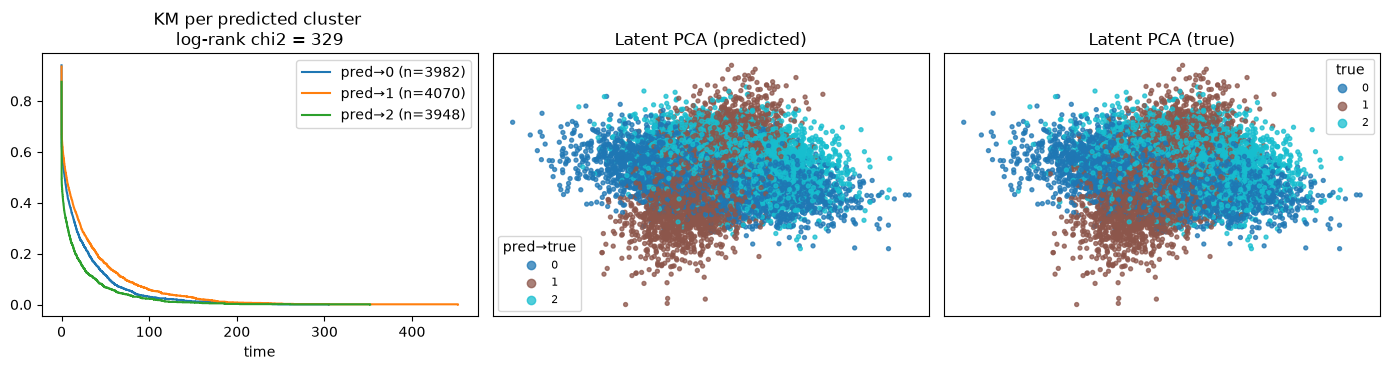

true,0,1,2
predicted,,,
0,3348,346,288
1,350,3436,284
2,285,282,3381


In [ ]:
from scipy.optimize import linear_sum_assignment

ari = adjusted_rand_score(sim.clusters_true_te, clusters)
print(f"ARI(VaDeSC, true) = {ari:.3f} | log-rank chi2 = {logrank_chi2(sim, clusters):.1f}")

# Align predicted IDs to true labels.
cont = pd.crosstab(clusters, sim.clusters_true_te)
r, c = linear_sum_assignment(-cont.to_numpy())
mapping = {cont.index[i]: cont.columns[j] for i, j in zip(r, c)}
clusters_plot = np.vectorize(mapping.get)(clusters)
print("label map (pred → true):", mapping)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for k in np.unique(clusters_plot):
    m = clusters_plot == k
    KaplanMeierFitter(label=f"pred→{k} (n={m.sum()})").fit(sim.t_te[m], sim.e_te[m]) \
        .plot_survival_function(ax=ax[0], ci_show=False)
ax[0].set(title=f"KM per predicted cluster \nlog-rank chi2 = {logrank_chi2(sim, clusters):.0f}",
          xlabel="time")

p2 = PCA(2).fit_transform(z_te)
sc0 = ax[1].scatter(p2[:, 0], p2[:, 1], c=clusters_plot, s=8, cmap="tab10", alpha=0.75)
ax[1].set(title="Latent PCA (predicted)", xticks=[], yticks=[])
ax[1].legend(*sc0.legend_elements(), title="pred→true", loc="best", fontsize=8)

sc1 = ax[2].scatter(p2[:, 0], p2[:, 1], c=sim.clusters_true_te, s=8, cmap="tab10", alpha=0.75)
ax[2].set(title=f"Latent PCA (true)", xticks=[], yticks=[])
ax[2].legend(*sc1.legend_elements(), title="true", loc="best", fontsize=8)
plt.tight_layout(); plt.show()

pd.crosstab(pd.Series(clusters_plot, name="predicted"),
            pd.Series(sim.clusters_true_te, name="true"))